In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import zipfile

from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [3]:
df = pd.read_csv("/content/archive (2).zip")

In [4]:
df

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,virginica
146,6.3,2.5,5.0,1.9,virginica
147,6.5,3.0,5.2,2.0,virginica
148,6.2,3.4,5.4,2.3,virginica


In [5]:
df.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [6]:
df.tail()

,sepal_length,sepal_width,petal_length,petal_width,species
145,6.7,3.0,5.2,2.3,virginica
146,6.3,2.5,5.0,1.9,virginica
147,6.5,3.0,5.2,2.0,virginica
148,6.2,3.4,5.4,2.3,virginica
149,5.9,3.0,5.1,1.8,virginica


In [7]:
df.describe()

,sepal_length,sepal_width,petal_length,petal_width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.054000,3.758667,1.198667
std,0.828066,0.433594,1.764420,0.763161
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


In [8]:
df.shape

(150, 5)

In [9]:
df.dtypes

,0
sepal_length,float64
sepal_width,float64
petal_length,float64
petal_width,float64
species,object


In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB


In [11]:
# Input features: sepal and petal measurements
X = df[['sepal_length', 'sepal_width', 'petal_length', 'petal_width']]

# Target: flower species
y = df['species']

print("Features (X):")
display(X.head())
print("Target (y):")
display(y.head())

Features (X):


,sepal_length,sepal_width,petal_length,petal_width
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


Target (y):


,species
0,setosa
1,setosa
2,setosa
3,setosa
4,setosa


In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 120
Testing records: 30


In [13]:
model = GaussianNB()
model.fit(X_train, y_train)

print("Gaussian Naive Bayes model trained successfully.")

Gaussian Naive Bayes model trained successfully.


In [14]:
y_pred = model.predict(X_test)

results = X_test.copy()
results['Actual Species'] = y_test
results['Predicted Species'] = y_pred
display(results.head(10))

,sepal_length,sepal_width,petal_length,petal_width,Actual Species,Predicted Species
38,4.4,3.0,1.3,0.2,setosa,setosa
127,6.1,3.0,4.9,1.8,virginica,virginica
57,4.9,2.4,3.3,1.0,versicolor,versicolor
93,5.0,2.3,3.3,1.0,versicolor,versicolor
42,4.4,3.2,1.3,0.2,setosa,setosa
56,6.3,3.3,4.7,1.6,versicolor,versicolor
22,4.6,3.6,1.0,0.2,setosa,setosa
20,5.4,3.4,1.7,0.2,setosa,setosa
147,6.5,3.0,5.2,2.0,virginica,virginica
84,5.4,3.0,4.5,1.5,versicolor,versicolor


In [15]:
# Enter the flower measurements in this order:
# sepal_length, sepal_width, petal_length, petal_width
test_flower = pd.DataFrame(
    [[5.1, 3.5, 1.4, 0.2]],
    columns=['sepal_length', 'sepal_width', 'petal_length', 'petal_width']
)

prediction = model.predict(test_flower)[0]
probabilities = model.predict_proba(test_flower)[0]

print("Test flower measurements:")
display(test_flower)
print("Predicted species:", prediction)
print("\nPrediction probabilities:")
for species, probability in zip(model.classes_, probabilities):
    print(f"{species}: {probability * 100:.2f}%")

Test flower measurements:


,sepal_length,sepal_width,petal_length,petal_width
0,5.1,3.5,1.4,0.2


Predicted species: setosa

Prediction probabilities:
setosa: 100.00%
versicolor: 0.00%
virginica: 0.00%


In [16]:
accuracy = accuracy_score(y_test, y_pred)
print(f"Testing Accuracy: {accuracy * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Testing Accuracy: 96.67%

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



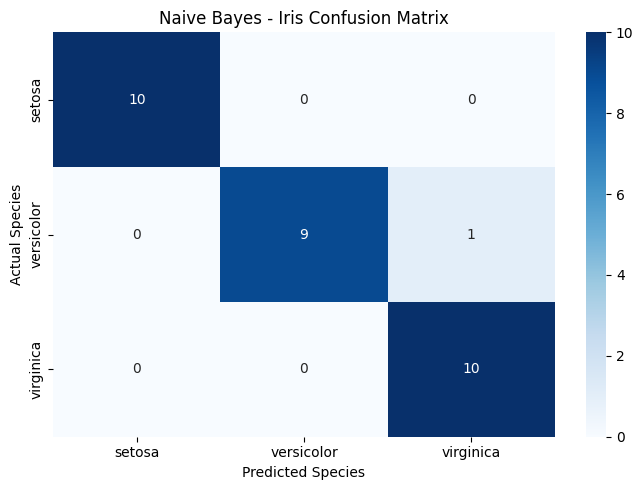

In [17]:
cm = confusion_matrix(y_test, y_pred, labels=model.classes_)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues',
    xticklabels=model.classes_, yticklabels=model.classes_
)
plt.xlabel("Predicted Species")
plt.ylabel("Actual Species")
plt.title("Naive Bayes - Iris Confusion Matrix")
plt.tight_layout()
plt.show()

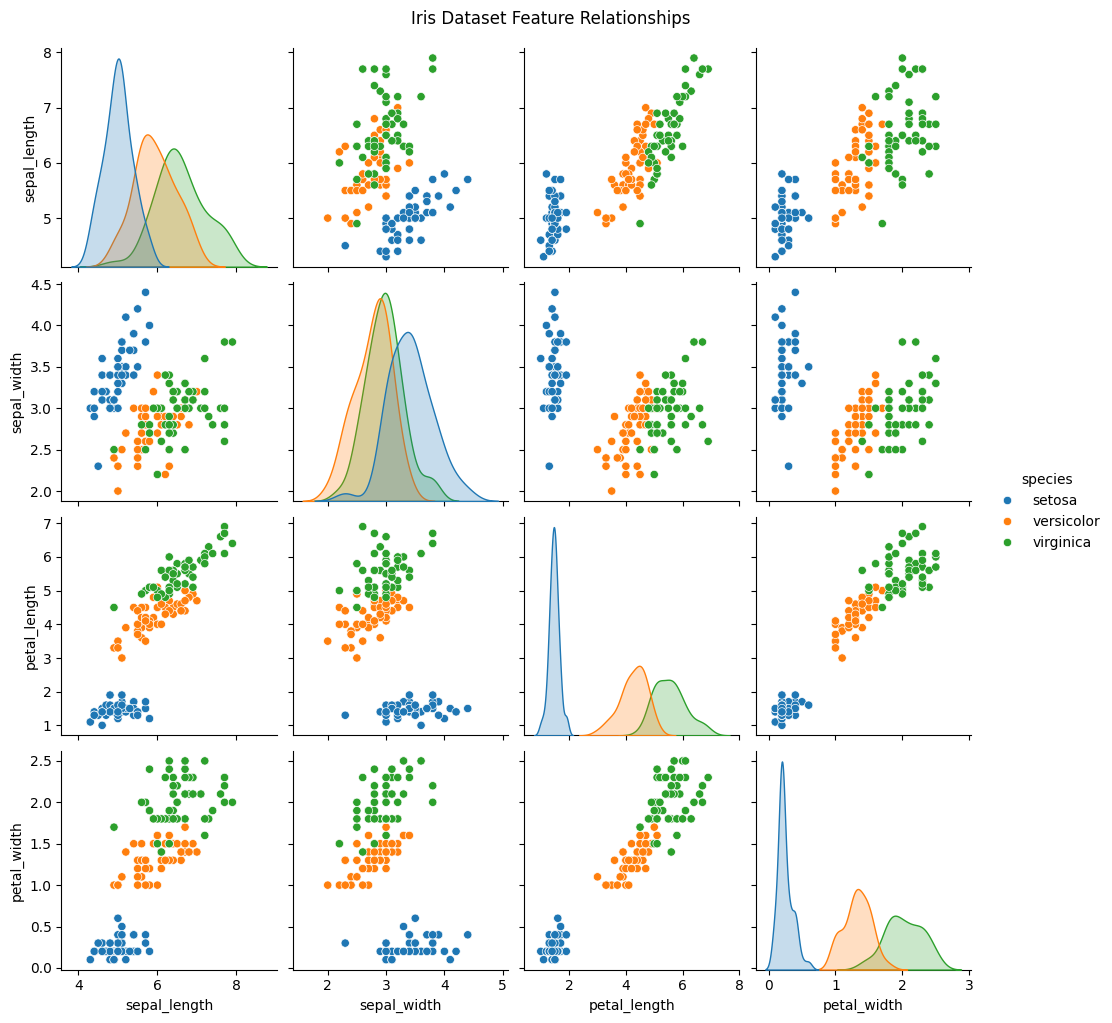

In [18]:
sns.pairplot(df, hue='species')
plt.suptitle("Iris Dataset Feature Relationships", y=1.02)
plt.show()